<a href="https://colab.research.google.com/github/DiesMorgan/PorfolioEjercicios/blob/main/MORGAN_DIEGO_COMISION_252613_TPI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Integrador — Pre-Entrega SynthData

**Alumno:** Diego Morgan

**Comisión:** 252613

## Datasets provistos (ANEXO)

Los archivos cargados para desarrollar este TPI son:

- [`ventas.csv`](https://docs.google.com/spreadsheets/d/1LohsWlzXWu9OqJ9Y5fmJAVf5Js_3-NZro_DDNagGJKU/edit?gid=2010662296#gid=2010662296)
- [`marketing.csv`](https://docs.google.com/spreadsheets/d/1qQ8AAB3x8jBDqde8OwmhsRvKgh9l1XubMsvlrtMw3h8/edit?gid=182182342#gid=182182342)
- [`clientes.csv`
](https://docs.google.com/spreadsheets/d/1hozu_OUZtByBioP7dB5MmYq6stiZjl2N8cSYdGWnYE8/edit?gid=2120849380#gid=2120849380)

## ETAPA 1 — Recopilación y Preparación de Datos

In [ ]:
# Actividad 1

import pandas as pd
#Cargar los datasets
ventas_df = pd.read_csv('https://docs.google.com/spreadsheets/d/1LohsWlzXWu9OqJ9Y5fmJAVf5Js_3-NZro_DDNagGJKU/export?format=csv&gid=2010662296')
marketing_df = pd.read_csv('https://docs.google.com/spreadsheets/d/1qQ8AAB3x8jBDqde8OwmhsRvKgh9l1XubMsvlrtMw3h8/export?format=csv&gid=182182342')
clientes_df = pd.read_csv('https://docs.google.com/spreadsheets/d/1hozu_OUZtByBioP7dB5MmYq6stiZjl2N8cSYdGWnYE8/export?format=csv&gid=2120849380')
# Muestrar cantidad de filas y columnas
print("Cargas realizadas:")
print("ventas:", ventas_df.shape)
print("marketing:", marketing_df.shape)
print("clientes:", clientes_df.shape)
# Muestrar nombres de las columnas
print("\nColumnas ventas:", list(ventas_df.columns))
print("Columnas marketing:", list(marketing_df.columns))
print("Columnas clientes:", list(clientes_df.columns))

Cargas realizadas:
ventas: (3035, 6)
marketing: (90, 6)
clientes: (567, 5)

Columnas ventas: ['id_venta', 'producto', 'precio', 'cantidad', 'fecha_venta', 'categoria']
Columnas marketing: ['id_campanha', 'producto', 'canal', 'costo', 'fecha_inicio', 'fecha_fin']
Columnas clientes: ['id_cliente', 'nombre', 'edad', 'ciudad', 'ingresos']


In [ ]:
# Actividad 2

# Borrar el signo $ y convertir en float los precios
ventas_df['precio'] = ventas_df['precio'].replace({r'\$': ''}, regex=True).astype(float)
# Calcular las ventas acumuladas
venta_acumuladas = (ventas_df['precio'] * ventas_df['cantidad']).sum()
# Formatear el monto con dos decimales y separadores de miles (estilo norteamericano porque si no tenía que importar una biblioteca que desconozco jeje)
resultado_formateado = f"Venta acumulada: ${venta_acumuladas:,.2f}"
# Imprime la totalidad de las ventas acumuladas
print(resultado_formateado)

Venta acumulada: $1,483,042.93


In [ ]:
# Actividad 3
#Hacer un nuevo dataframe con una tabla de columnas seleccionadas
seleccion = ['producto', 'precio', 'cantidad']
seleccion_df = ventas_df[seleccion]
print("--- Selección de ventas ---")

print (seleccion_df)

--- Selección de ventas ---
                    producto  precio  cantidad
0          Cuadro decorativo   69.94       5.0
1            Lámpara de mesa  105.10       5.0
2                   Secadora   97.96       3.0
3                   Heladera  114.35       8.0
4                   Secadora  106.21       4.0
...                      ...     ...       ...
3030         Horno eléctrico  104.12       9.0
3031                  Laptop   85.27       9.0
3032                  Laptop  107.81       4.0
3033              Smartphone   99.85       7.0
3034  Consola de videojuegos   55.47       6.0

[3035 rows x 3 columns]


In [ ]:
# Actividad 4
# Aplicar info() para familiarizarnos con el dataframe
marketing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_campanha   90 non-null     int64  
 1   producto      90 non-null     object 
 2   canal         90 non-null     object 
 3   costo         90 non-null     float64
 4   fecha_inicio  90 non-null     object 
 5   fecha_fin     90 non-null     object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.3+ KB


In [ ]:
# Visualizar los primeros registros con head()
marketing_df.head()

,id_campanha,producto,canal,costo,fecha_inicio,fecha_fin
0,74,Adorno de pared,TV,4.81,20/03/2024,03/05/2024
1,12,Tablet,RRSS,3.40,26/03/2024,13/05/2024
2,32,Lámpara de mesa,Email,5.54,28/03/2024,20/04/2024
3,21,Smartphone,RRSS,6.37,29/03/2024,16/05/2024
4,58,Alfombra,Email,4.25,31/03/2024,05/05/2024


In [ ]:
# también podemos usar tail() para visualizar los últimos
marketing_df.tail()

,id_campanha,producto,canal,costo,fecha_inicio,fecha_fin
85,70,Aspiradora,TV,3.06,13/12/2024,29/12/2024
86,89,Televisor,TV,4.98,13/12/2024,8/2/2025
87,68,Rincón de plantas,TV,5.81,17/12/2024,14/2/2025
88,33,Secadora,Email,3.80,20/12/2024,7/1/2025
89,11,Freidora eléctrica,RRSS,5.27,29/12/2024,21/1/2025


In [ ]:
# Usar sample() para tomar registros al azar
marketing_df.sample(7)

,id_campanha,producto,canal,costo,fecha_inicio,fecha_fin
18,76,Lavadora,TV,4.66,26/05/2024,02/07/2024
9,84,Parlantes Bluetooth,TV,4.42,17/04/2024,05/05/2024
60,13,Cortinas,RRSS,5.22,16/09/2024,15/10/2024
59,52,Elementos de cerámica,Email,5.74,09/09/2024,30/09/2024
5,85,SmartWatch,TV,5.07,01/04/2024,05/05/2024
39,53,Espejo decorativo,Email,4.90,17/07/2024,01/08/2024
64,86,Microondas,TV,4.25,25/09/2024,15/11/2024


In [ ]:
# Analizar el campo costo
# Si es numericos se puede aplicar describe()
marketing_df["costo"].describe()

,costo
count,90.000000
mean,4.928667
std,0.947750
min,2.950000
25%,4.372500
50%,4.900000
75%,5.562500
max,7.390000


In [ ]:
# Analizar el campo producto
# si es numerico se puede aplicar describe()
marketing_df["producto"].sample(5)

,producto
68,Candelabro
79,Auriculares
26,Freidora eléctrica
87,Rincón de plantas
33,Heladera


In [ ]:
# Analizar el campo fecha_inicio
marketing_df["fecha_inicio"].sample(5)

,fecha_inicio
37,16/07/2024
63,25/09/2024
56,27/08/2024
78,05/11/2024
64,25/09/2024


In [ ]:
# Analizar el campo categoria
marketing_df["canal"].value_counts()

,count
canal,
TV,30
RRSS,30
Email,30


In [ ]:
# Probar con unique
marketing_df["canal"].unique()

array(['TV', 'RRSS', 'Email'], dtype=object)

In [ ]:
# Actividad 5
# Buscar registros duplicados
clientes_df.duplicated().sum()

np.int64(0)

In [ ]:
# Visualizar los duplicados
# keep: 'first', 'last', False
clientes_df[clientes_df.duplicated(keep=False)].sort_values(by="nombre")

,id_cliente,nombre,edad,ciudad,ingresos


In [ ]:
# Buscar datos nulos
clientes_df.isnull().sum()

,0
id_cliente,0
nombre,0
edad,0
ciudad,0
ingresos,0


In [ ]:
# Visualizar los nulos
clientes_df[clientes_df.isnull().any(axis=1)]

,id_cliente,nombre,edad,ciudad,ingresos


In [ ]:
# Analizar los ingresos de los NaN a ver que opciones tenemos
clientes_df["ingresos"].value_counts()



,count
ingresos,
3603.65,2
36720.12,2
35394.54,2
35552.30,2
36611.51,2
...,...
39719.87,1
6619.38,1
18074.87,1


In [ ]:
# clientes_df ["ingresos"].unique()
clientes_df["ingresos"].unique()

array([42294.68, 24735.04, 35744.85, 27647.96, 28245.65, 62763.31,
       37489.71, 35255.94, 27592.08, 37153.94, 35596.27, 41862.78,
       56171.38, 14690.68, 42168.75, 16480.55, 47018.78, 32826.37,
       53114.05, 49849.42, 42000.81,  9085.92, 46734.23, 39770.63,
       25917.58, 27928.46, 36720.12, 33220.06, 41813.93, 44137.9 ,
       21063.82, 54193.68, 33986.78, 28615.26, 27136.93, 52128.76,
       25838.89, 42757.46, 36779.95, 28333.21, 43388.14, 39243.17,
       30237.01, 29665.37, 20234.81, 20880.07, 29914.53, 25017.77,
       39132.63, 31056.32, 39896.32,  7901.16, 45641.94, 37690.42,
       19065.49,  3603.65, 61296.09, 30978.96, 30800.4 , 60027.71,
       33894.6 , 49215.7 , 51773.22, 37077.23, 46549.39, 27487.51,
       33401.67, 57501.45, 27271.1 , 46525.97, 31514.23, 35486.9 ,
       53758.89, 22895.21, 19996.54,  8756.53, 34822.1 , 35205.04,
       37982.47, 50757.4 , 43948.65, 46088.54, 19009.84, 29249.16,
       36166.55, 25454.48, 34918.69, 45912.27, 50428.21,   170

## ETAPA 2 — Preprocesamiento y Limpieza de Datos


In [ ]:
#Actividad 1

print("--- DOCUMENTACIÓN DEL PROCESO DE LIMPIEZA DE VENTAS ---")

# Limpieza de duplicados
# Conteo inicial de filas
filas_iniciales = len(ventas_df)
# Capturar los índices de las filas que serán eliminadas (todas menos la primera ocurrencia)
# Esto es para la documentación, el conteo de duplicados a eliminar
indices_a_eliminar = ventas_df[ventas_df.duplicated(keep='first')].index
duplicados_a_eliminar_count = len(indices_a_eliminar)
# Eliminar duplicados y actualizar el DataFrame original
ventas_df.drop_duplicates(inplace=True)
# Conteo final de filas
filas_finales = len(ventas_df)
print(f"\n1. ELIMINACIÓN DE FILAS DUPLICADAS:")
print(f"   - Filas iniciales: {filas_iniciales}")
print(f"   - Filas duplicadas ELIMINADAS: {duplicados_a_eliminar_count}")
print(f"   - Filas finales (después de la limpieza): {filas_finales}")
# Documentación adicional: Mostrar los índices de las filas eliminadas
print(f"   - Índices de las filas duplicadas que fueron eliminadas: {list(indices_a_eliminar)}")

# Limpieza de caractéres no deseados
# Seleccionar solo las columnas de tipo 'object' (texto)
columnas_texto = ventas_df.select_dtypes(include=['object']).columns
print(f"\n2. LIMPIEZA Y ESTANDARIZACIÓN DE CARACTERES (En columnas: {list(columnas_texto)})")
for col in columnas_texto:
    # Eliminar espacios en blanco al inicio y final
    ventas_df[col] = ventas_df[col].str.strip()
    # Convertir a mayúsculas (estandarización)
    ventas_df[col] = ventas_df[col].str.upper()
    # Eliminar caracteres especiales/no deseados
    # Usamos r'' para evitar SyntaxWarning (cadena raw)
    # Eliminar todo lo que no sea una letra A-Z, un número 0-9, un espacio, una arroba o un punto.
    ventas_df[col] = ventas_df[col].str.replace(r'[^A-Z0-9\s@\.]', '', regex=True)
print("   - Estandarización aplicada: Eliminación de espacios, conversión a MAYÚSCULAS y limpieza de símbolos.")

# Resultado final
print("\n--- RESUMEN DEL DATASET LIMPIO ---")
print("Primeras 5 filas del DataFrame limpio:")
print(ventas_df.head())
print(f"\nDataFrame limpio tiene {len(ventas_df)} filas y {ventas_df.shape[1]} columnas.")

--- DOCUMENTACIÓN DEL PROCESO DE LIMPIEZA DE VENTAS ---

1. ELIMINACIÓN DE FILAS DUPLICADAS:
   - Filas iniciales: 3035
   - Filas duplicadas ELIMINADAS: 35
   - Filas finales (después de la limpieza): 3000
   - Índices de las filas duplicadas que fueron eliminadas: [826, 827, 828, 829, 830, 831, 844, 845, 846, 847, 848, 849, 850, 851, 852, 853, 854, 855, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 884, 885, 886, 887, 888, 889]

2. LIMPIEZA Y ESTANDARIZACIÓN DE CARACTERES (En columnas: ['producto', 'fecha_venta', 'categoria'])
   - Estandarización aplicada: Eliminación de espacios, conversión a MAYÚSCULAS y limpieza de símbolos.

--- RESUMEN DEL DATASET LIMPIO ---
Primeras 5 filas del DataFrame limpio:
   id_venta           producto  precio  cantidad fecha_venta         categoria
0       792  CUADRO DECORATIVO   69.94       5.0    02012024         DECORACIN
1       811     LMPARA DE MESA  105.10       5.0    02012024         DECORACIN
2      1156           SECADORA   97.96  

In [ ]:
# Actividad 2

# Pasar a numérico el tipo de dato
ventas_df['precio'] = pd.to_numeric(ventas_df['precio'], errors='coerce')
ventas_df['cantidad'] = pd.to_numeric(ventas_df['cantidad'], errors='coerce')

# Agregar columna de venta_acumulada
ventas_df['venta_acumulada'] = ventas_df['precio'] * ventas_df['cantidad']

# Calcular las totalidad de las ventas acumuladas
venta_acumuladas_total = ventas_df['venta_acumulada'].sum()
resultado_formateado = f"Venta acumulada: ${venta_acumuladas_total:,.2f}"
print(resultado_formateado)


# Alto rendimiento = ingreso total de la venta por encima del promedio general de las ventas y la cantidad vendida por encima de la cantidad promedio vendida
# Calcular umbrales de rendimiento
promedio_venta = ventas_df['venta_acumulada'].mean()
promedio_cantidad = ventas_df['cantidad'].mean()
# Definir la condición de alto rendimiento (AND/OR entre paréntesis)
filtro_alto_rendimiento = (
    (ventas_df['venta_acumulada'] > promedio_venta) |
    (ventas_df['cantidad'] > promedio_cantidad)
)
# Crear la nueva tabla filtrada
ventas_alto_rendimiento_df = ventas_df[filtro_alto_rendimiento].copy()

# Opcional: mostrar la cantidad de filas seleccionadas
print(f"El umbral de Ingreso Promedio es: ${promedio_venta:,.2f}")
print(f"El umbral de Cantidad Promedio es: {promedio_cantidad:,.2f} unidades")
print(f"Total de ventas clasificadas como de Alto Rendimiento: {len(ventas_alto_rendimiento_df)} filas.")

print("\n--- TABLA DE VENTAS DE ALTO RENDIMIENTO (Primeras 5 Filas) ---")
print(ventas_alto_rendimiento_df.head())

Venta acumulada: $1,467,093.52
El umbral de Ingreso Promedio es: $489.36
El umbral de Cantidad Promedio es: 6.50 unidades
Total de ventas clasificadas como de Alto Rendimiento: 1703 filas.

--- TABLA DE VENTAS DE ALTO RENDIMIENTO (Primeras 5 Filas) ---
   id_venta          producto  precio  cantidad fecha_venta         categoria  \
1       811    LMPARA DE MESA  105.10       5.0    02012024         DECORACIN   
3      1372          HELADERA  114.35       8.0    02012024  ELECTRODOMSTICOS   
5      1697    HORNO ELCTRICO   35.35       9.0    02012024  ELECTRODOMSTICOS   
7      2959         PROYECTOR   88.17       9.0    02012024        ELECTRNICA   
8       318  RINCN DE PLANTAS   79.86      11.0    03012024         DECORACIN   

   venta_acumulada  
1           525.50  
3           914.80  
5           318.15  
7           793.53  
8           878.46  


In [ ]:
# Actividad 3
# Asegurar que la columna de Venta Total exista
if 'venta_acumulada' not in ventas_df.columns:
    ventas_df['venta_acumulada'] = ventas_df['precio'] * ventas_df['cantidad']

# Agrupar por 'producto' y calcular la suma de la venta y la cantidad
resumen_por_producto = ventas_df.groupby('producto').agg(
    total_ingresos=('venta_acumulada', 'sum'),
    total_cantidad=('cantidad', 'sum'),
    cantidad_transacciones=('producto', 'size') # Contar cuántas ventas hubo por producto
).reset_index()

# Ordenar el resumen por el ingreso total (de mayor a menor)
resumen_por_producto = resumen_por_producto.sort_values(
    by='total_ingresos',
    ascending=False
)

# Formatear la columna de ingresos para una mejor visualización (con separadores de miles y 2 decimales)
resumen_por_producto['total_ingresos_formato'] = resumen_por_producto['total_ingresos'].apply(
    lambda x: f"${x:,.2f}"
)

print("--- ANÁLISIS DE INGRESOS AGREGADOS POR PRODUCTO (Top 5) ---")
print(resumen_por_producto[['producto', 'total_ingresos_formato', 'total_cantidad', 'cantidad_transacciones']].head())

print(f"\nTotal de categorías de productos analizadas: {len(resumen_por_producto)}")

--- ANÁLISIS DE INGRESOS AGREGADOS POR PRODUCTO (Top 5) ---
             producto total_ingresos_formato  total_cantidad  \
19     LMPARA DE MESA             $82,276.38          1112.0   
3         AURICULARES             $74,175.58           958.0   
20         MICROONDAS             $72,562.89           912.0   
5            CAFETERA             $59,607.31           765.0   
10  CUADRO DECORATIVO             $54,297.60           726.0   

    cantidad_transacciones  
19                     176  
3                      143  
20                     135  
5                      117  
10                     100  

Total de categorías de productos analizadas: 30


In [ ]:
# Actividad 4 (con mucha ayuda de IA porque hay conceptos de tendencia que no comprendí)
# La clave de unión es 'producto'.
# Usaremos 'left' merge para mantener todas las ventas y añadir la información de marketing.
datos_integrados_df = pd.merge(
    ventas_df,
    marketing_df[['producto', 'canal', 'costo', 'fecha_inicio', 'fecha_fin']], # agregamos fecha_inicio and fecha_fin
    on='producto',
    how='left'
)

# --- Análisis Ampliado (Tendencias Integradas) ---

# Calcular el Costo Total de Marketing por Venta
# Para simplificar, asumiremos que 'costo' es el costo unitario de marketing por producto.
datos_integrados_df['costo_total_marketing'] = (
    datos_integrados_df['costo'] * datos_integrados_df['cantidad']
)

# Calcular el Margen Bruto (Ingreso Total - Costo Total de Marketing)
# Use 'venta_acumulada' instead of 'ingreso_total'
datos_integrados_df['margen_bruto'] = (
    datos_integrados_df['venta_acumulada'] - datos_integrados_df['costo_total_marketing']
)

# Resumir el Margen Bruto por Canal de Venta para identificar tendencias
resumen_por_canal = datos_integrados_df.groupby('canal').agg(
    margen_bruto_total=('margen_bruto', 'sum'),
    # Use 'venta_acumulada' instead of 'ingreso_total'
    ingreso_total_sum=('venta_acumulada', 'sum'),
    transacciones=('id_venta', 'size')
).sort_values(by='margen_bruto_total', ascending=False).reset_index()

print("\n--- INTEGRACIÓN Y TENDENCIA: MARGEN BRUTO POR CANAL DE MARKETING ---")
print(f"Dimensiones del DataFrame Integrado: {datos_integrados_df.shape}")
resumen_por_canal['margen_bruto_total_formato'] = resumen_por_canal['margen_bruto_total'].apply(lambda x: f"${x:,.2f}")
print(resumen_por_canal[['canal', 'margen_bruto_total_formato', 'transacciones']])


--- INTEGRACIÓN Y TENDENCIA: MARGEN BRUTO POR CANAL DE MARKETING ---
Dimensiones del DataFrame Integrado: (3000, 14)
Empty DataFrame
Columns: [canal, margen_bruto_total_formato, transacciones]
Index: []


# Trabajo Práctico Integrador — Entrega Final SynthData

**Alumno:** Diego Morgan

**Comisión:** 252613

## Datasets provistos (ANEXO)

Los archivos cargados para desarrollar este TPI son:

- [`ventas.csv`](https://docs.google.com/spreadsheets/d/1LohsWlzXWu9OqJ9Y5fmJAVf5Js_3-NZro_DDNagGJKU/edit?gid=2010662296#gid=2010662296)
- [`marketing.csv`](https://docs.google.com/spreadsheets/d/1qQ8AAB3x8jBDqde8OwmhsRvKgh9l1XubMsvlrtMw3h8/edit?gid=182182342#gid=182182342)
- [`clientes.csv`
](https://docs.google.com/spreadsheets/d/1hozu_OUZtByBioP7dB5MmYq6stiZjl2N8cSYdGWnYE8/edit?gid=2120849380#gid=2120849380)

## ETAPA 3 —

1 - Estadística Descriptiva
Calcular medidas de tendencia central y dispersión sobre las ventas. Presentar los resultados en un informe

In [ ]:
#Actividad 1
# Dataframe ventas
ventas_df[["precio", "cantidad", "venta_acumulada"]].describe()
# ventas_df.describe()

,precio,cantidad,venta_acumulada
count,2998.000000,2998.000000,2998.000000
mean,75.291318,6.502668,489.357412
std,28.736008,3.455107,334.281817
min,26.000000,1.000000,26.300000
25%,50.030000,3.000000,220.920000
50%,75.205000,7.000000,418.065000
75%,100.067500,9.000000,709.920000
max,124.970000,12.000000,1488.120000


In [ ]:
marketing_df.head()

,id_campanha,producto,canal,costo,fecha_inicio,fecha_fin
0,74,Adorno de pared,TV,4.81,20/03/2024,03/05/2024
1,12,Tablet,RRSS,3.40,26/03/2024,13/05/2024
2,32,Lámpara de mesa,Email,5.54,28/03/2024,20/04/2024
3,21,Smartphone,RRSS,6.37,29/03/2024,16/05/2024
4,58,Alfombra,Email,4.25,31/03/2024,05/05/2024


In [ ]:
# Dataframe marketing
marketing_df.groupby("canal")["costo"].describe()

,count,mean,std,min,25%,50%,75%,max
canal,,,,,,,,
Email,30.0,4.840000,0.898773,2.95,4.2125,4.895,5.5075,6.84
RRSS,30.0,5.030333,0.894101,3.16,4.5600,5.130,5.5425,7.16
TV,30.0,4.915667,1.063215,3.06,4.3725,4.795,5.5400,7.39


2 - EDA (Análisis Exploratorio de Datos)
Realizar un análisis exploratorio utilizando visualizaciones para identificar patrones y tendencias en las ventas.

Gráficos histogramas

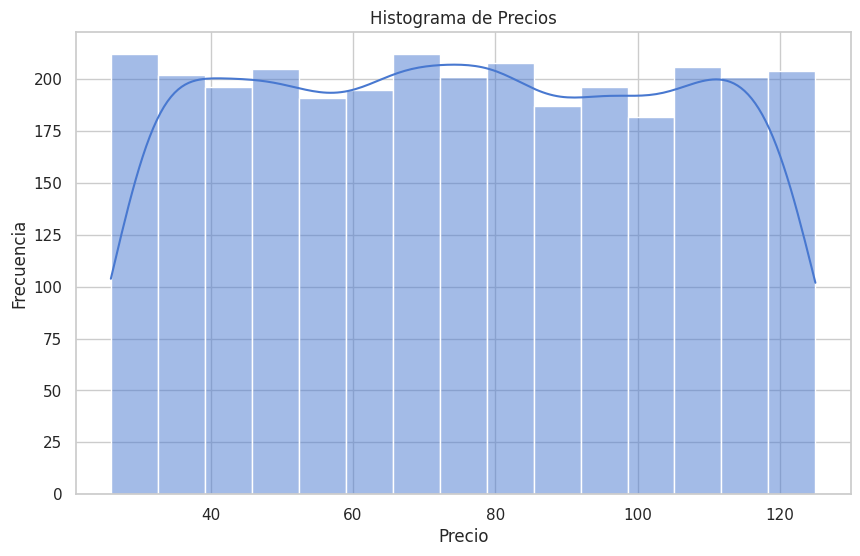

In [ ]:
# Importar bibliotecas no utilizadas aún

import seaborn as sns
import matplotlib.pyplot as plt

# Estilo y tamaños
sns.set_theme(style="whitegrid", palette="muted") # deep, muted, bright, Set1, Set2, Set3
plt.figure(figsize=(10, 6))

# Graficamos
sns.histplot(data=ventas_df, x="precio", bins="auto", kde=True)

# Títulos y leyendas
plt.title("Histograma de Precios")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()

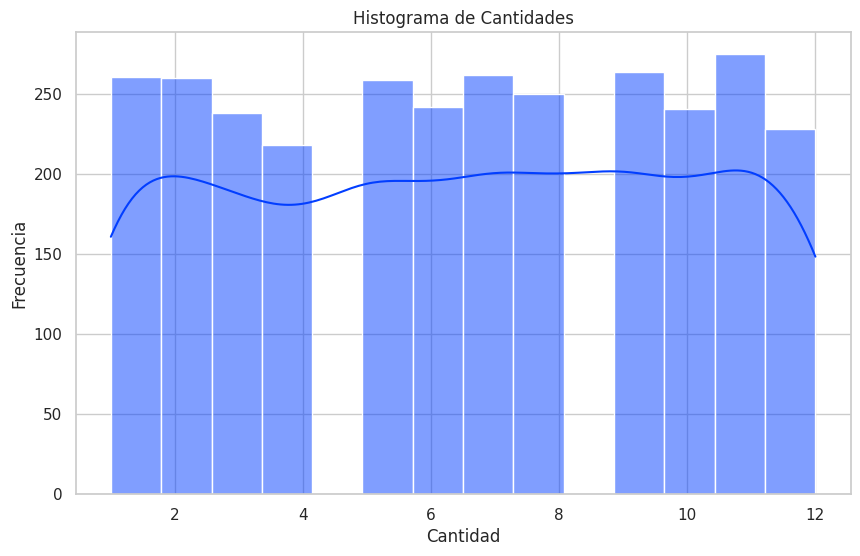

In [ ]:
# Histograma cantidades

# Estilo y tamaños
sns.set_theme(style="whitegrid", palette="bright") # deep, muted, bright, Set1, Set2, Set3
plt.figure(figsize=(10, 6))

# Graficamos
sns.histplot(data=ventas_df, x="cantidad", bins="auto", kde=True)

# Títulos y leyendas
plt.title("Histograma de Cantidades")
plt.xlabel("Cantidad")
plt.ylabel("Frecuencia")
plt.show()


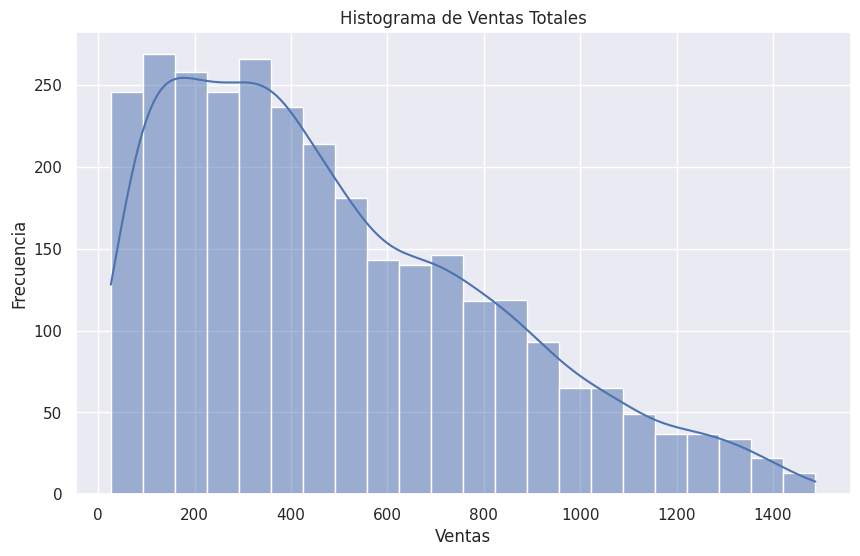

In [ ]:
# Histograma ventas_totales

# Estilo y tamaños
sns.set_theme(style="darkgrid", palette="deep") # deep, muted, bright, Set1, Set2, Set3
plt.figure(figsize=(10, 6))

# Graficamos
sns.histplot(data=ventas_df, x="venta_acumulada", bins="auto", kde=True)

# Títulos y leyendas
plt.title("Histograma de Ventas Totales")
plt.xlabel("Ventas")
plt.ylabel("Frecuencia")
plt.show()

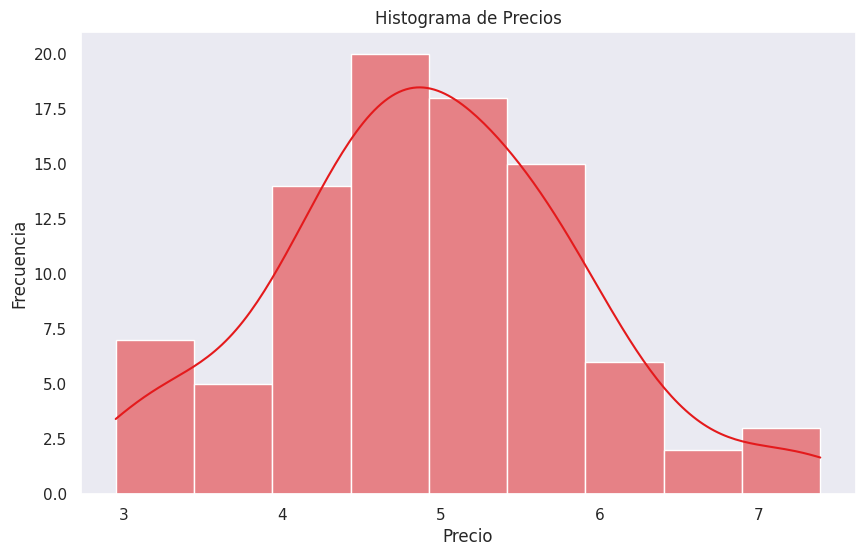

In [ ]:
# Histograma costo marketing

# Estilo y tamaños
sns.set_theme(style="dark", palette="Set1") # deep, muted, bright, Set1, Set2, Set3
plt.figure(figsize=(10, 6))

# Graficamos
sns.histplot(data=marketing_df, x="costo", bins="auto", kde=True)

# Títulos y leyendas
plt.title("Histograma de Precios")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()


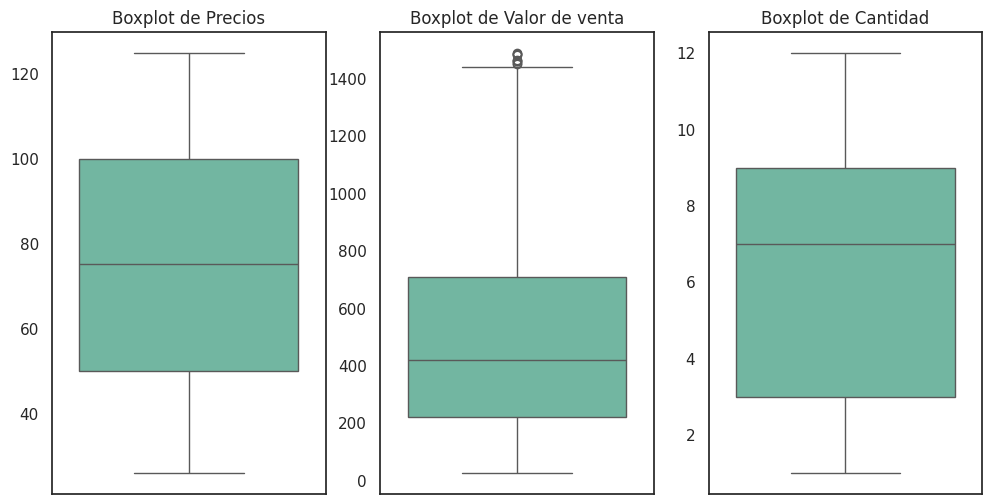

In [ ]:
# Boxplot Ventas

# Estilo y tamaños
sns.set_theme(style="white", palette="Set2") # deep, muted, bright, Set1, Set2, Set3
plt.figure(figsize=(12, 6)) #ancho x alto = resolucion

# Subplots, dividen al lienzo en partes
plt.subplot(1,3,1) # (1,3,1) => (1 fila, 3 columnas, bloque 1)

# Subplot 1
sns.boxplot(data=ventas_df, y="precio")
plt.title("Boxplot de Precios")
plt.ylabel("")

# Subplot 2
plt.subplot(1,3,2) # (1,3,2) => (1 fila, 3 columnas, bloque 2)
sns.boxplot(data=ventas_df, y="venta_acumulada")
plt.title("Boxplot de Valor de venta")
plt.ylabel("")


# Subplot 3
plt.subplot(1,3,3) # (1,3,3) => (1 fila, 3 columnas, bloque 3)
sns.boxplot(data=ventas_df, y="cantidad")
plt.title("Boxplot de Cantidad")
plt.ylabel("")

plt.show()



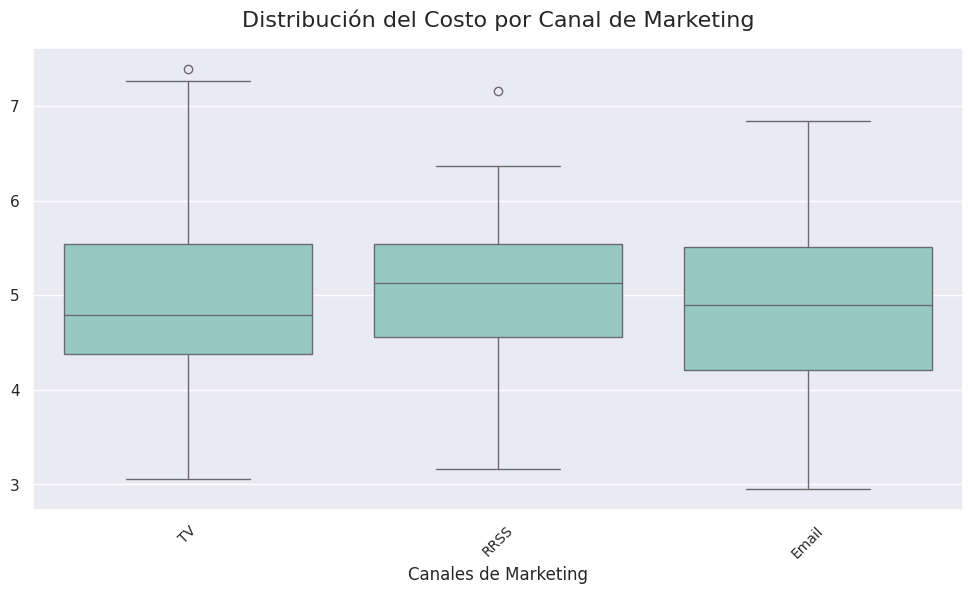

In [ ]:
# Boxplot marketing

# Estilo y tamaños
sns.set_theme(style="darkgrid", palette="Set3") # deep, muted, bright, Set1, Set2, Set3
plt.figure(figsize=(12, 6))

# Graficamos
sns.boxplot(data=marketing_df, x="canal", y="costo")
# sns.boxplot(data=df_marketing, y="costo") # asi grafico costo para todos los canales

# Título y subtítulo
plt.title("Distribución del Costo por Canal de Marketing", fontsize=16, pad=15)

plt.xlabel("Canales de Marketing", fontsize=12)
plt.ylabel("")

# Rotación y tamaño de labels del eje X
plt.xticks(rotation=45, fontsize=10)

plt.show()



3 - Correlación

In [ ]:
# Primero calculamos la matríz de correlación usando las variables numéricas
correlacion = ventas_df[['precio', 'cantidad', 'venta_acumulada']].corr() #.corr() calcula la matriz de correlacion
print("\nMatriz de correlación:")
print(correlacion)


Matriz de correlación:
                   precio  cantidad  venta_acumulada
precio           1.000000 -0.002388         0.558846
cantidad        -0.002388  1.000000         0.773009
venta_acumulada  0.558846  0.773009         1.000000


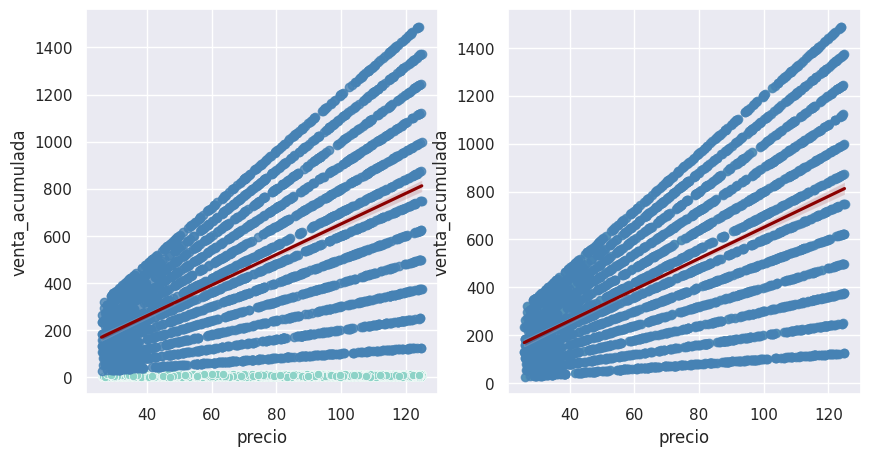

In [ ]:
# Representamos las variables en un scatterplot o gráfico de dispersión
# Y agregamos una línea de tendencia

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.scatterplot(data=ventas_df, x="precio", y="cantidad")

# agrega una linea de regresion
sns.regplot(
    data=ventas_df,
    x="precio",
    y="venta_acumulada",
    color="steelblue",
    line_kws={"color": "darkred", "label": "Recta de regresión"}
)

plt.subplot(1,2,2)
sns.scatterplot(data=ventas_df, x="precio", y="venta_acumulada")
sns.regplot(
    data=ventas_df,
    x="precio",
    y="venta_acumulada",
    color="steelblue",
    line_kws={"color": "darkred", "label": "Recta de regresión"}
)


plt.show()

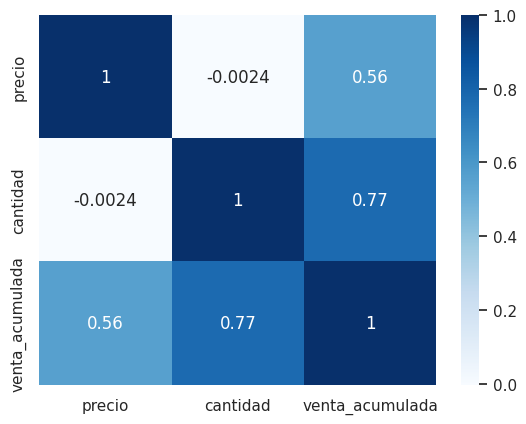

In [ ]:
# Creamos un mapa de calor para representar la matríz de correlación
sns.heatmap(correlacion, annot=True, cmap="Blues") # cmap = Blues, Greens, rocket
plt.show()

4 - Consolidación de datos
Consolidar todos los análisis previos y preparar un conjunto de datos final que resuma los hallazgos clave para la presentación.

In [ ]:
ventas_df.head(5)

,id_venta,producto,precio,cantidad,fecha_venta,categoria,venta_acumulada
0,792,CUADRO DECORATIVO,69.94,5.0,02012024,DECORACIN,349.70
1,811,LMPARA DE MESA,105.10,5.0,02012024,DECORACIN,525.50
2,1156,SECADORA,97.96,3.0,02012024,ELECTRODOMSTICOS,293.88
3,1372,HELADERA,114.35,8.0,02012024,ELECTRODOMSTICOS,914.80
4,1546,SECADORA,106.21,4.0,02012024,ELECTRODOMSTICOS,424.84


In [ ]:
# Generamos primero la columna mes
# Convertir la columna 'fecha_venta' a tipo datetime
ventas_df['fecha_venta'] = pd.to_datetime(ventas_df['fecha_venta'], format='%d%m%Y')
ventas_df["mes"] = ventas_df["fecha_venta"].dt.month

# Agrupamos por mes y agregamos por valor_venta
ventas_mes = ventas_df.groupby("mes", as_index=False).agg(
    ventas_mes=("venta_acumulada", "sum")
)

# Renombramos la columna si fuera necesario
# ventas_mes = ventas_mes.rename(columns={
#     "mes": "mes",
#     "ventas_totales": "ventas_totales"
# })

# Visualizamos
ventas_mes.head()

,mes,ventas_mes
0,1,129604.99
1,2,118672.44
2,3,136779.15
3,4,128430.69
4,5,143727.25


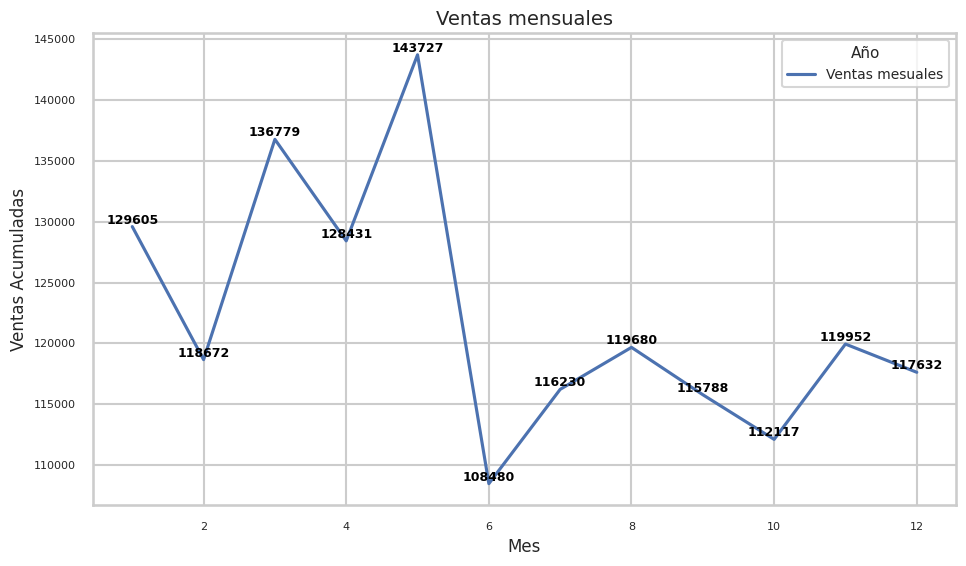

In [ ]:


# Estilo
sns.set_theme(style="whitegrid", context="talk")
custom_palette = sns.color_palette("Set2") # Aqui pueden cambiar a "Set1", "Set2", "Set3"

# Definimos el tamaño del lienzo
plt.figure(figsize=(10,6))

# Graficamos
ax = sns.lineplot(data=ventas_mes, x="mes", y="ventas_mes", label="Ventas mesuales" )

# Ticks (valores de eje)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

# --- Agregar etiquetas de valores sobre cada punto ---
for x, y in zip(ventas_mes["mes"], ventas_mes["ventas_mes"]):
    ax.text(
        x, y,
        f"{y:.0f}",       # etiqueta (sin decimales)
        ha="center",
        va="bottom",      # posición arriba del punto
        fontsize=9,
        color="black",
        fontweight="bold"
    )

# Ajustes de título y ejes
plt.title('Ventas mensuales', fontsize=14)
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Ventas Acumuladas', fontsize=12)
plt.legend(title='Año', fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()

Cantidad de productos totales vendidos por mes

In [ ]:
# Agrupamos por mes y agregamos por cantidad
cantidades_mes = ventas_df.groupby("mes", as_index=False).agg(
    cantidad_mes=("cantidad", "sum")
)

# Visualizamos
cantidades_mes.head()

,mes,cantidad_mes
0,1,1741.0
1,2,1607.0
2,3,1792.0
3,4,1715.0
4,5,1812.0


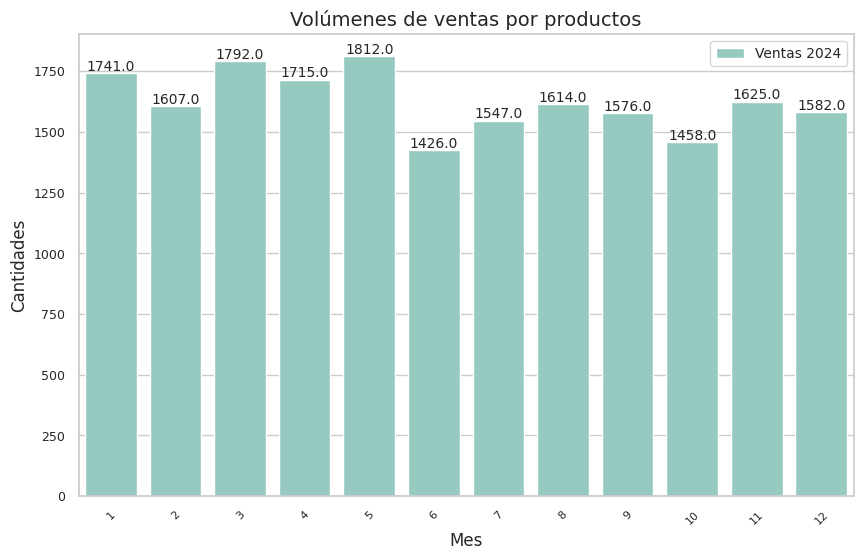

In [ ]:
# Estilo y paleta
sns.set_theme(               # set_theme combina estilo + contexto + paleta
    style="whitegrid",       # opciones: 'white', 'whitegrid', 'dark', 'darkgrid', 'ticks'
    context="notebook",          # escala general: 'paper', 'notebook', 'talk', 'poster'
    palette="Set3"           # paleta de colores base: "deep", "muted", "pastel" / Set1, Set2, Set3
)

# Ajustamos tamaño del lienzo
plt.figure(figsize=(10,6))

# Crear el barplot
ax = sns.barplot(data=cantidades_mes, x='mes', y='cantidad_mes', label="Ventas 2024", width=0.8)

# Agregar etiquetas arriba de las barras
for i, valor in enumerate(cantidades_mes['cantidad_mes']):
    ax.text(
        i,                       # posición x de la etiqueta
        valor + 10,                   # posición y (ligeramente arriba de la barra)
        str(valor),              # texto
        ha='center', fontsize=10
    )

# Ticks (valores de eje)
plt.tick_params(axis='y', labelsize=9)
plt.tick_params(axis='x', rotation=45,  labelsize=8)

# Ajustes de título y ejes
plt.title('Volúmenes de ventas por productos', fontsize=14)
plt.xlabel('Mes')
plt.ylabel('Cantidades')
plt.legend(loc='upper right', fontsize=10)
# plt.tight_layout() # ajuste automatico
plt.show()

Volumen de venta por categorías

In [ ]:
# Agrupamos por categoría y agregamos por valor_venta
ventas_categoria = ventas_df.groupby("categoria", as_index=False).agg(
    ventas_totales=("venta_acumulada", "sum")
)

# Visualizamos
ventas_categoria.head()

,categoria,ventas_totales
0,DECORACIN,479216.09
1,ELECTRNICA,482577.80
2,ELECTRODOMSTICOS,505299.63


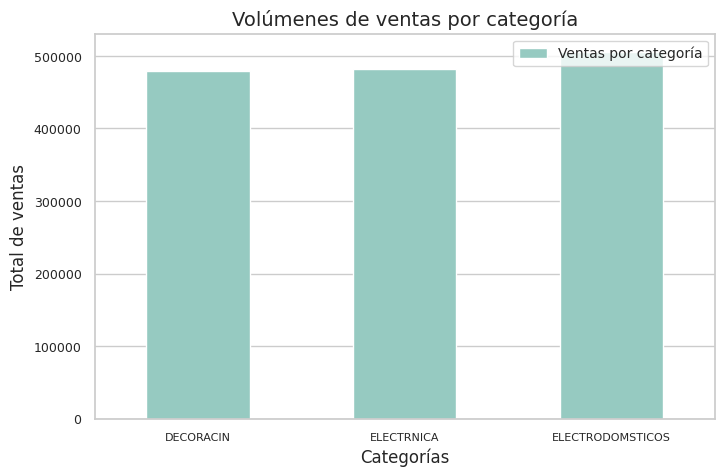

In [ ]:
# Estilo y paleta
sns.set_theme(               # set_theme combina estilo + contexto + paleta
    style="whitegrid",       # opciones: 'white', 'whitegrid', 'dark', 'darkgrid', 'ticks'
    context="notebook",          # escala general: 'paper', 'notebook', 'talk', 'poster'
    palette="Set3"           # paleta de colores base: "deep", "muted", "pastel" / Set1, Set2, Set3
)

# Ajustamos tamaño del lienzo
plt.figure(figsize=(8,5))

# Crear el barplot
ax = sns.barplot(data=ventas_categoria, x='categoria', y='ventas_totales', label="Ventas por categoría", width=0.5)


# Ticks (valores de eje)
plt.tick_params(axis='y', labelsize=9)
plt.tick_params(axis='x', labelsize=8)

# Ajustes de título y ejes
plt.title('Volúmenes de ventas por categoría', fontsize=14)
plt.xlabel('Categorías')
plt.ylabel('Total de ventas')
plt.legend(loc='upper right', fontsize=10)
# plt.tight_layout() # ajuste automatico
plt.show()

Impacto de la campaña de marketing en las ventas

In [ ]:
# Veamos el inicio de la primer campaña de marketing
datos_integrados_df[["fecha_venta","fecha_inicio", "fecha_fin" ]].describe()

,fecha_venta,fecha_inicio,fecha_fin
count,3000,0,0
mean,2024-06-26 19:21:36,NaT,NaT
min,2024-01-02 00:00:00,NaT,NaT
25%,2024-03-27 00:00:00,NaT,NaT
50%,2024-06-24 00:00:00,NaT,NaT
75%,2024-09-27 00:00:00,NaT,NaT
max,2024-12-30 00:00:00,NaT,NaT


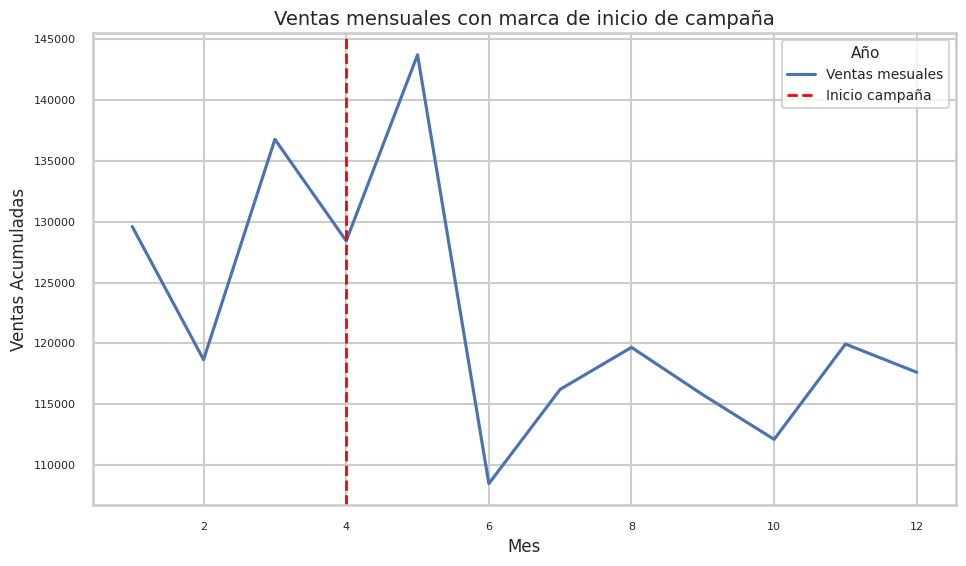

In [ ]:
# Generamos un gráfico de lineas (serie de tiempo)
# que muestre la evolución de las ventas en el año (2024 por mes)
# Y le trazamos una linea vertical en el mes 4 (la primera campaña fue el 20 de marzo)

# Estilo
sns.set_theme(style="whitegrid", context="talk")
custom_palette = sns.color_palette("Set1") # Aqui pueden cambiar a "Set1", "Set2", "Set3"

# Definimos el tamaño del lienzo
plt.figure(figsize=(10,6))

# Graficamos
sns.lineplot(data=ventas_mes, x="mes", y="ventas_mes", label="Ventas mesuales")

# línea vertical que marque el inicio de campaña
plt.axvline(4, color="red", linewidth=2, linestyle="--",
            label="Inicio campaña")

# Ticks (valores de eje)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

# Ajustes de título y ejes
plt.title('Ventas mensuales con marca de inicio de campaña', fontsize=14)
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Ventas Acumuladas', fontsize=12)
plt.legend(title='Año', fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()

## ETAPA 4 — Conclusiones


In [ ]:
marketing_df['producto'] = marketing_df['producto'].str.upper()

merged_ventas_marketing_df = pd.merge(
    ventas_df,
    marketing_df[['producto', 'canal', 'costo', 'fecha_inicio', 'fecha_fin']],
    on='producto',
    how='left'
)

# Display the head of the new merged DataFrame to verify the merge
print("Head of merged_sales_marketing_df:")
print(merged_ventas_marketing_df.head())

Head of merged_sales_marketing_df:
   id_venta           producto  precio  cantidad fecha_venta  \
0       792  CUADRO DECORATIVO   69.94       5.0  2024-01-02   
1       792  CUADRO DECORATIVO   69.94       5.0  2024-01-02   
2       792  CUADRO DECORATIVO   69.94       5.0  2024-01-02   
3       811     LMPARA DE MESA  105.10       5.0  2024-01-02   
4      1156           SECADORA   97.96       3.0  2024-01-02   

          categoria  venta_acumulada  mes  canal  costo fecha_inicio  \
0         DECORACIN           349.70    1   RRSS   5.27   27/04/2024   
1         DECORACIN           349.70    1  Email   5.28   15/08/2024   
2         DECORACIN           349.70    1     TV   5.30   05/11/2024   
3         DECORACIN           525.50    1    NaN    NaN          NaN   
4  ELECTRODOMSTICOS           293.88    1   RRSS   5.10   24/07/2024   

    fecha_fin  
0  04/06/2024  
1  12/09/2024  
2  23/12/2024  
3         NaN  
4  30/08/2024  
